In [7]:
import plotly as pl
import matplotlib.pyplot as plt
import seaborn as s
import matplotlib as mp
import numpy as np
import pandas as pd
import os
import pathlib

notebook_dir = pathlib.Path().resolve()
print(notebook_dir)

/Users/teoboy/101_python/intro_to_statistics/pew-global-attitudes-2024-analysis


In [11]:
pew = pd.read_csv("pew_dataset.csv", dtype=str) 

In [12]:
# convert relevant columns to numeric

pew['weight'] = pd.to_numeric(pew['weight'], errors='coerce')
pew['age'] = pd.to_numeric(pew['age'], errors='coerce')  
pew['id'] = pd.to_numeric(pew['id'], errors='coerce')  
pew['country'] = pd.to_numeric(pew['country'], errors='coerce') 

# create a python dictionary, generating an additional 'country' column from country-codes

country_code_map = {
    2: "Canada",
    3: "France",
    4: "Germany",
    5: "Greece",
    6: "Hungary",
    7: "Italy",
    8: "Netherlands",
    9: "Poland",
    10: "Spain",
    11: "Sweden",
    12: "UK",
    13: "Australia",
    14: "Bangladesh",
    15: "India",
    16: "Indonesia",
    17: "Japan",
    18: "Malaysia",
    19: "Philippines",
    20: "Singapore",
    21: "South Korea",
    22: "Sri Lanka",
    23: "Thailand",
    24: "Israel",
    25: "Tunisia",
    26: "Turkey",
    27: "Ghana",
    28: "Kenya",
    29: "Nigeria",
    30: "South Africa",
    31: "Argentina",
    32: "Brazil",
    33: "Chile",
    34: "Colombia",
    35: "Mexico",
    36: "Peru"
}

pew['country_name'] = pew['country'].map(country_code_map)

# 1. Literature Review

China is often referenced, especially across Europe and the US, when talking about censorship and freedom, in addition to winning the AI arms race. But is there a correlation between global attitudes and opinions towards China, and views of internet freedom, press freedom and tech governance?


## Research Question: How do perceptions of China correlate with views on internet freedom, press freedom, and technology governance?

### Potential Analysis Directions:

1. **China Favorability vs. Internet Freedom Views**: Do people with favorable views of China also have different perspectives on internet freedom/censorship?
   
2. **Technocracy and China**: Does support for technocracy (rule by technology experts) correlate with views on China, especially given China's technological development model?

3. **Misinformation Concerns**: How do concerns about misinformation (which increasingly involves AI-generated content) relate to perceptions of China and internet freedom?

4. **Country-Level Patterns**: Are there regional patterns where countries with more restrictive internet policies have different views on China?

# 2. Methodology

## 2.1 Research Question

**Main Question**: How do perceptions of China correlate with attitudes toward internet freedom, press freedom, and technology governance (technocracy)?

**Sub-questions**:
1. Do people with favorable views of China have different attitudes toward internet censorship compared to those with unfavorable views?
2. Does support for technocracy (rule by technology experts) relate to perceptions of China?
3. How do concerns about misinformation relate to views on both China and internet freedom?

## 2.2 Dataset

**Key Variables:

**China Perceptions**:
- `fav_china` (ALL): Please tell me if you have a very favorable (1), somewhat favorable (2), somewhat unfavorable (3), or very unfavorable (4) opinion of china?
- `fav_us` (ALL): Please tell me if you have a very favorable (1), somewhat favorable (2), somewhat unfavorable (3), or very unfavorable (4) opinion of china?
- `uspres_china` (ALL): thinking about U.S. president Joe Biden, do you strongly approve (1), somewhat approve (2), somewhat disapprove (3) or strongly disapprove (4) of the way he is dealing with China?
- `china_influ_econ` (ALL): How much influence do you think China is having on economic conditions in your country — a great deal of influence (1), a fair amount of influence (2), not too much influence (3), or no influence at all (4)?
- `china_influ_econ2` (ALL): If answer to the previous question was (1), (2), or (3), is China having a positive (1) or negative (2) or neither/both (3) impacts on economic conditions in your country?

**Internet/Freedom Variables**:
- `free_press` (ALL): How free is the media to report the news? Completely (1), somewhat (2), not very (3), not at all (4)
- `free_say` (ALL): How free are people to say what they want? Completely (1), somewhat (2), not very (3), not at all (4)
- `free_internet` (ALL): How free are people to use the internet? Completely (1), somewhat (2), not very (3), not at all (4)
- `press_freedom` (ALL): How important is it that the media can report the news without state or government censorship? Very important (1), somewhat important (2), not too important (3) or not important at all (4)
- `free_speech` (ALL): How important is it that people can say what they want without state or government censorship? Very important (1), somewhat important (2), not too important (3) or not important at all (4)
- `internet_freedom` (ALL): How important is it that people can use the internet without state or government censorship? Very important (1), somewhat important (2), not too important (3) or not important at all (4)

**Governance & Technology**:
- `prob_misinformation` (ALL): How much of a problem do you think made-up news and information is in your country today - a very big problem (1), a moderately big problem (2), a small problem (3), or not a problem at all (4)?
- `inequality_automation` (ALL): How much, if at all, do you think robots and computers doing work previously done by humans leads to economic inequality in your country? A great deal (1), a fair amount (2), not too much (3), not at all (4)
- `satisfied_democracy` (ALL) - 'How satisfied are you with the way democracy is working in your country? very satisfied (1), somewhat satisfied (2), not too satisfied (3), or not at all satisfied (4)?' \
- `polsys_technocracy` (Limited to 20 countries, mainly global south): Do you think the idea of a technocracy would be good for governing your country? Very good (1), somewhat good (2), somewhat bad (3), very bad (4)

In [32]:
# 3. Analysis

## 3.1 China Favorability Across Countries

# Filter to valid responses (1-4) and ensure weight is numeric
valid_data = pew[pew['fav_china'].isin(['1', '2', '3', '4'])].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_china'])

# Calculate weighted proportions for each country
country_proportions = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # Calculate weighted counts for each response category
    weighted_counts = country_data.groupby('fav_china')['weight'].sum()
    proportions = (weighted_counts / total_weight) * 100
    
    # Convert Series to dict, handling missing values
    country_proportions[country] = {
        '1': proportions.get('1', 0) if '1' in proportions.index else 0,  # Very favorable
        '2': proportions.get('2', 0) if '2' in proportions.index else 0,  # Somewhat favorable
        '3': proportions.get('3', 0) if '3' in proportions.index else 0,  # Somewhat unfavorable
        '4': proportions.get('4', 0) if '4' in proportions.index else 0   # Very unfavorable
    }

# Create a summary: % favorable (1 or 2) vs unfavorable (3 or 4)
summary_stats = {}
for country, props in country_proportions.items():
    favorable_percent = props['1'] + props['2']  # Very + Somewhat favorable
    unfavorable_percent = props['3'] + props['4']  # Somewhat + Very unfavorable
    summary_stats[country] = {
        'Very Favorable': props['1'],
        'Somewhat Favorable': props['2'],
        'Somewhat Unfavorable': props['3'],
        'Very Unfavorable': props['4'],
        'Total Favorable': favorable_percent,
        'Total Unfavorable': unfavorable_percent
    }

# Convert to DataFrame for easier visualization
summary_df = pd.DataFrame(summary_stats).T
summary_df = summary_df.sort_values('Total Favorable', ascending=False)

print("China Favorability by Country (Weighted Proportions)")
print("=" * 90)
print(summary_df.round(1))



China Favorability by Country (Weighted Proportions)
              Very Favorable  Somewhat Favorable  Somewhat Unfavorable  \
Nigeria                 41.9                39.8                   8.2   
Thailand                21.9                59.3                  15.2   
Bangladesh              33.4                43.7                  11.3   
Kenya                   29.3                46.7                  12.4   
Sri Lanka               25.1                49.8                  12.5   
Tunisia                 22.7                50.3                  12.9   
Peru                    29.2                43.5                  14.3   
Singapore               14.7                52.8                  24.5   
Ghana                   36.5                29.6                  11.0   
Indonesia               13.4                51.6                  30.1   
Malaysia                15.8                48.2                  27.8   
Mexico                  16.2                47.8           

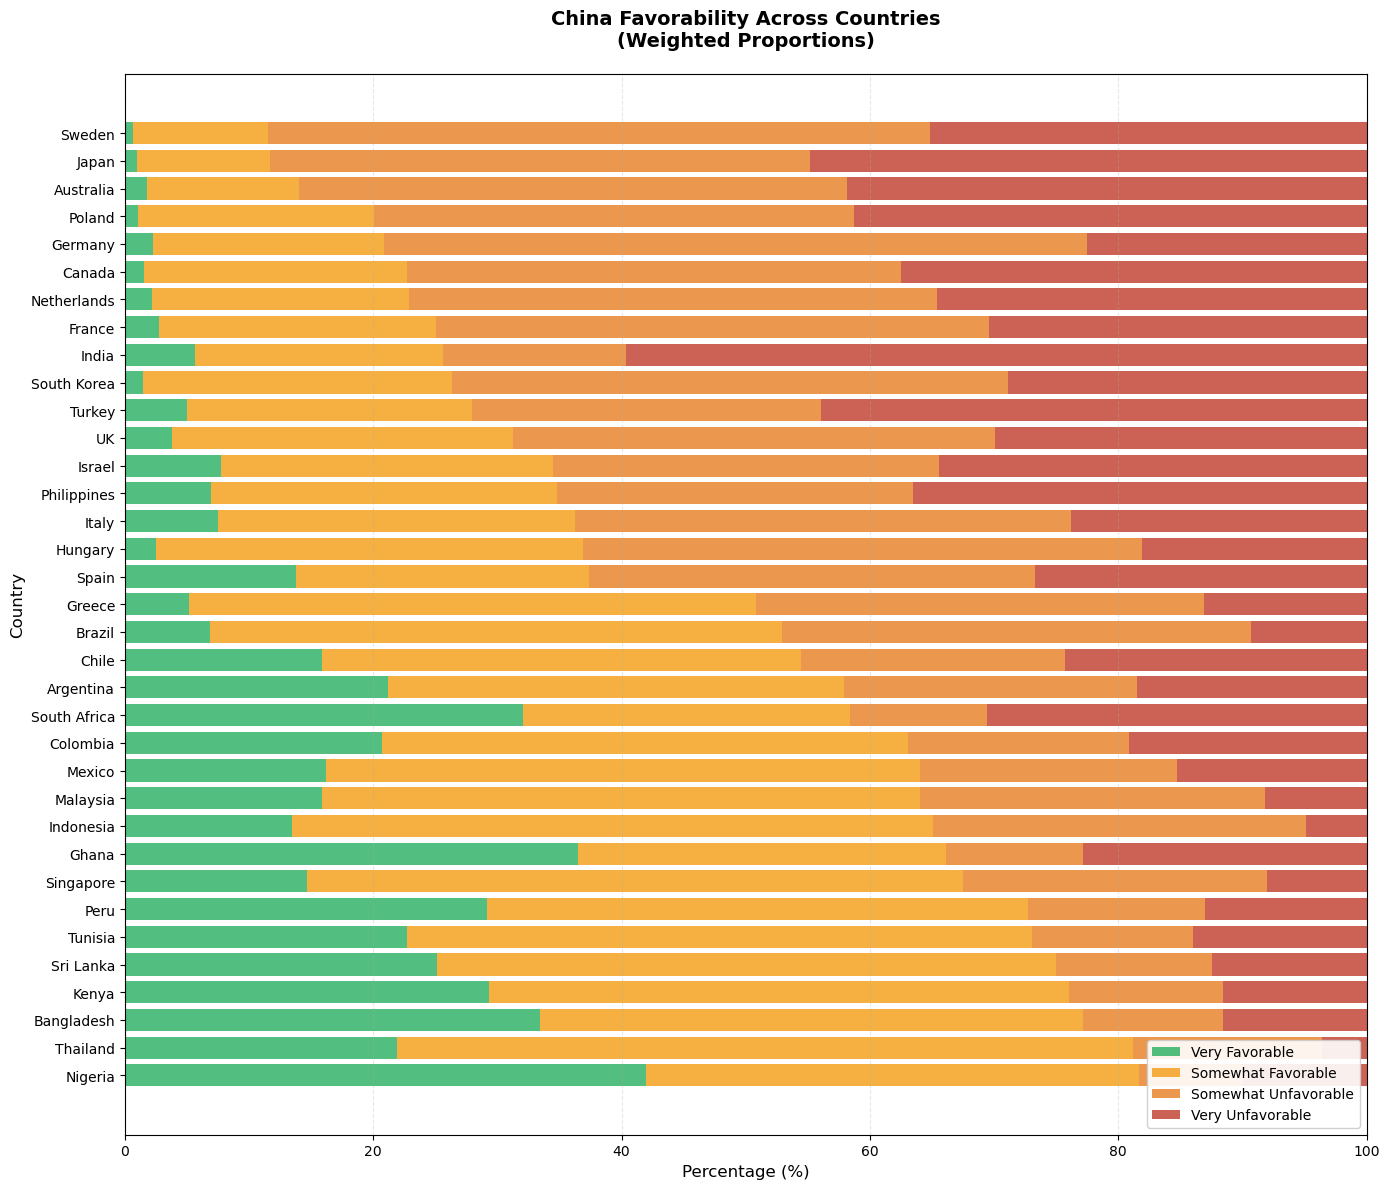

In [33]:
# Graph: China Favorability Across Countries
# Create a stacked horizontal bar chart

fig, ax = plt.subplots(figsize=(14, 12))

# Prepare data for stacked bar chart
countries = summary_df.index
categories = ['Very Favorable', 'Somewhat Favorable', 'Somewhat Unfavorable', 'Very Unfavorable']
colors = ['#27ae60', '#f39c12', '#e67e22', '#c0392b']  # Green to red gradient

# Create stacked bars
bottom = np.zeros(len(countries))
for category, color in zip(categories, colors):
    values = summary_df[category].values
    ax.barh(countries, values, left=bottom, label=category, color=color, alpha=0.8)
    bottom += values

ax.set_xlabel('Percentage (%)', fontsize=12)
ax.set_ylabel('Country', fontsize=12)
ax.set_title('China Favorability Across Countries\n(Weighted Proportions)', 
             fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='lower right', framealpha=0.9)
ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()


US Favorability by Country (Weighted Proportions)
              Very Favorable  Somewhat Favorable  Somewhat Unfavorable  \
Poland                  24.9                65.0                   8.2   
Ghana                   62.4                22.4                   7.4   
Colombia                25.9                54.4                  13.1   
South Korea             12.5                67.5                  18.0   
Kenya                   31.4                48.2                  10.0   
Thailand                19.1                59.8                  16.2   
Israel                  43.3                34.6                  11.7   
Nigeria                 43.4                34.1                   8.4   
India                   31.3                45.6                   8.7   
Peru                    19.6                56.5                  13.3   
Philippines             23.0                52.7                  18.9   
Sri Lanka               20.7                54.7              

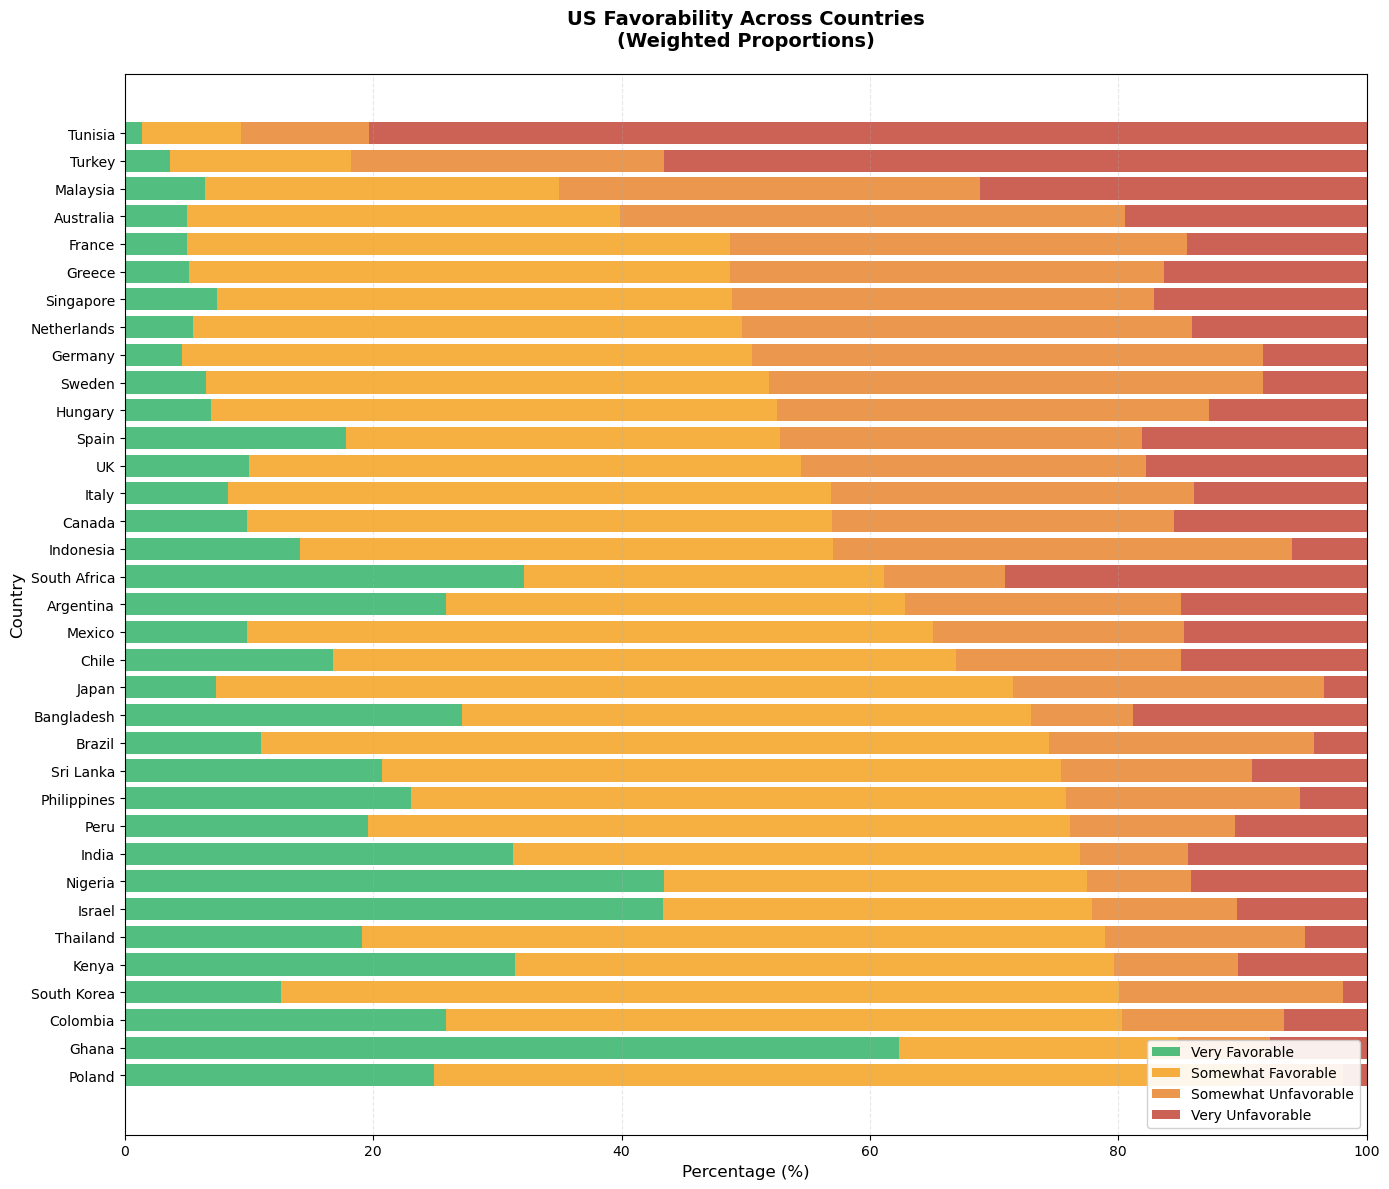

In [34]:
# Graph: China Favorability Across Countries
# Create a stacked horizontal bar chart

# 3. Analysis

## 3.1 China Favorability Across Countries

# Filter to valid responses (1-4) and ensure weight is numeric
valid_data = pew[pew['fav_us'].isin(['1', '2', '3', '4'])].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_us'])

# Calculate weighted proportions for each country
country_proportions = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # Calculate weighted counts for each response category
    weighted_counts = country_data.groupby('fav_us')['weight'].sum()
    proportions = (weighted_counts / total_weight) * 100
    
    # Convert Series to dict, handling missing values
    country_proportions[country] = {
        '1': proportions.get('1', 0) if '1' in proportions.index else 0,  # Very favorable
        '2': proportions.get('2', 0) if '2' in proportions.index else 0,  # Somewhat favorable
        '3': proportions.get('3', 0) if '3' in proportions.index else 0,  # Somewhat unfavorable
        '4': proportions.get('4', 0) if '4' in proportions.index else 0   # Very unfavorable
    }

# Create a summary: % favorable (1 or 2) vs unfavorable (3 or 4)
summary_stats = {}
for country, props in country_proportions.items():
    favorable_percent = props['1'] + props['2']  # Very + Somewhat favorable
    unfavorable_percent = props['3'] + props['4']  # Somewhat + Very unfavorable
    summary_stats[country] = {
        'Very Favorable': props['1'],
        'Somewhat Favorable': props['2'],
        'Somewhat Unfavorable': props['3'],
        'Very Unfavorable': props['4'],
        'Total Favorable': favorable_percent,
        'Total Unfavorable': unfavorable_percent
    }

# Convert to DataFrame for easier visualization
summary_df = pd.DataFrame(summary_stats).T
summary_df = summary_df.sort_values('Total Favorable', ascending=False)

print("US Favorability by Country (Weighted Proportions)")
print("=" * 90)
print(summary_df.round(1))

fig, ax = plt.subplots(figsize=(14, 12))

# Prepare data for stacked bar chart
countries = summary_df.index
categories = ['Very Favorable', 'Somewhat Favorable', 'Somewhat Unfavorable', 'Very Unfavorable']
colors = ['#27ae60', '#f39c12', '#e67e22', '#c0392b']  # Green to red gradient

# Create stacked bars
bottom = np.zeros(len(countries))
for category, color in zip(categories, colors):
    values = summary_df[category].values
    ax.barh(countries, values, left=bottom, label=category, color=color, alpha=0.8)
    bottom += values

ax.set_xlabel('Percentage (%)', fontsize=12)
ax.set_ylabel('Country', fontsize=12)
ax.set_title('US Favorability Across Countries\n(Weighted Proportions)', 
             fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='lower right', framealpha=0.9)
ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

UK Favorability by Country (Weighted Proportions)
              Very Favorable  Somewhat Favorable  Somewhat Unfavorable  \
Thailand                16.5                66.1                  13.1   
South Korea              6.3                75.4                  16.0   
Kenya                   27.0                53.4                  11.3   
Ghana                   48.3                30.9                  11.5   
Poland                  31.1                47.5                  15.7   
Sri Lanka               19.7                58.7                  13.0   
Bangladesh              26.3                48.9                  16.1   
Canada                  15.6                59.4                  16.0   
Colombia                27.2                47.4                  15.0   
Sweden                  21.2                53.4                  18.9   
Chile                   20.9                51.5                  15.1   
Peru                    21.1                51.2              

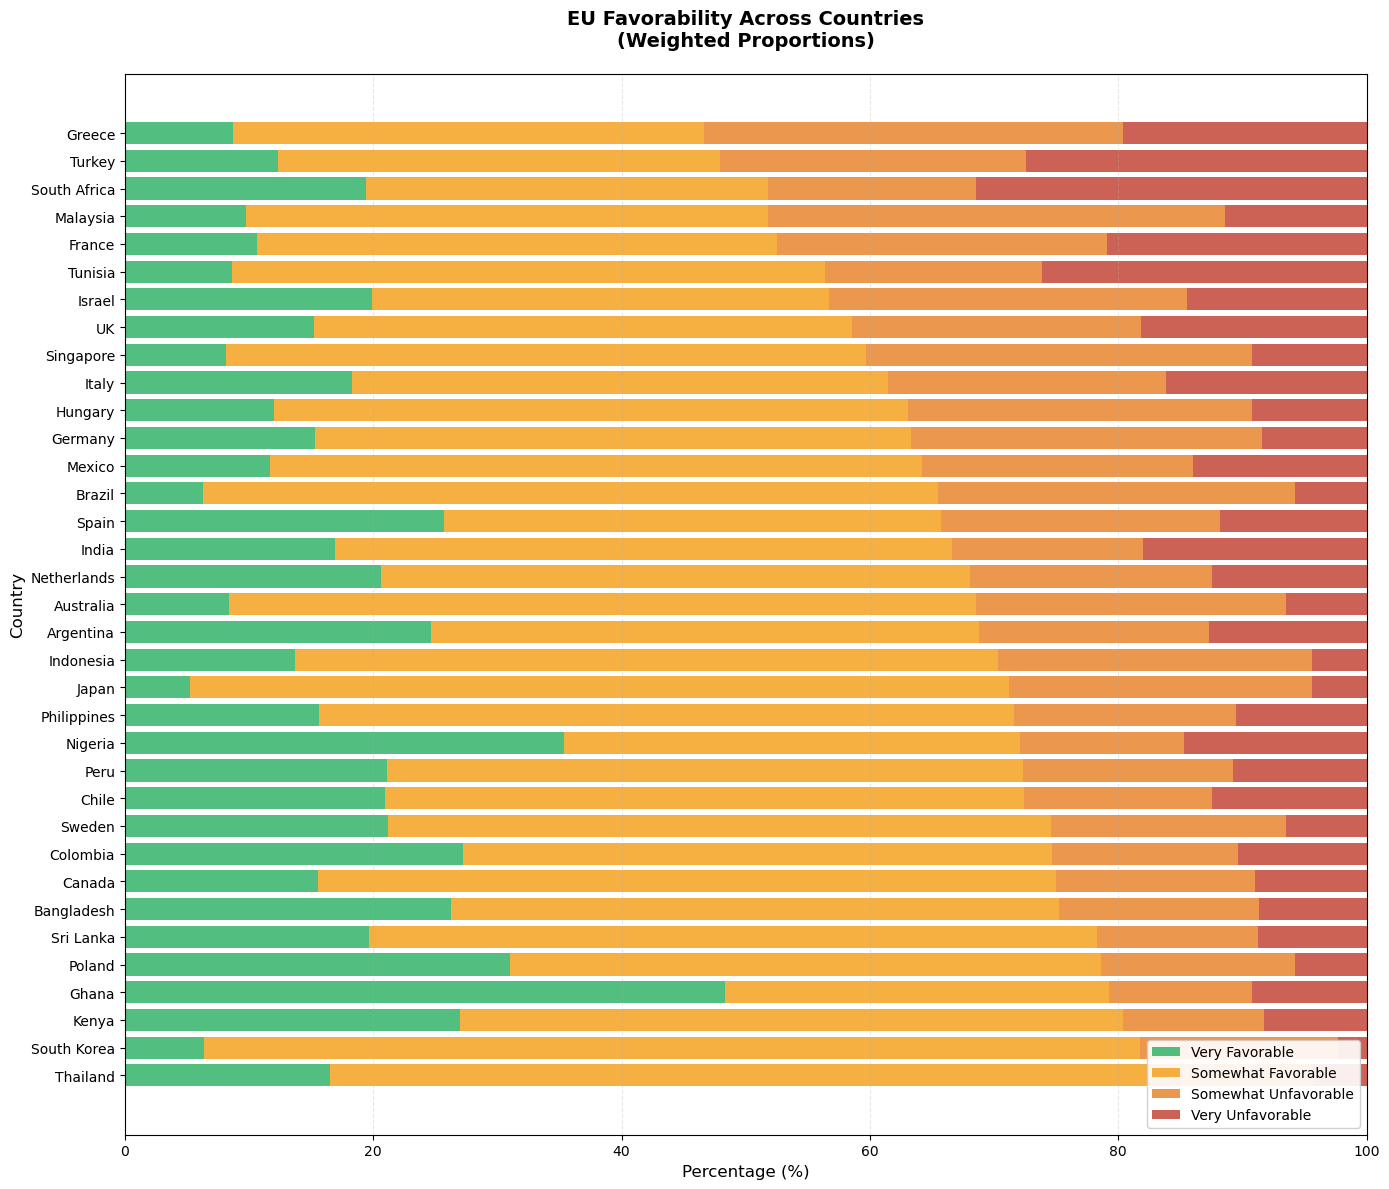

In [29]:
# Filter to valid responses (1-4) and ensure weight is numeric
valid_data = pew[pew['fav_eu'].isin(['1', '2', '3', '4'])].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_eu'])

# Calculate weighted proportions for each country
country_proportions = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # Calculate weighted counts for each response category
    weighted_counts = country_data.groupby('fav_eu')['weight'].sum()
    proportions = (weighted_counts / total_weight) * 100
    
    # Convert Series to dict, handling missing values
    country_proportions[country] = {
        '1': proportions.get('1', 0) if '1' in proportions.index else 0,  # Very favorable
        '2': proportions.get('2', 0) if '2' in proportions.index else 0,  # Somewhat favorable
        '3': proportions.get('3', 0) if '3' in proportions.index else 0,  # Somewhat unfavorable
        '4': proportions.get('4', 0) if '4' in proportions.index else 0   # Very unfavorable
    }

# Create a summary: % favorable (1 or 2) vs unfavorable (3 or 4)
summary_stats = {}
for country, props in country_proportions.items():
    favorable_percent = props['1'] + props['2']  # Very + Somewhat favorable
    unfavorable_percent = props['3'] + props['4']  # Somewhat + Very unfavorable
    summary_stats[country] = {
        'Very Favorable': props['1'],
        'Somewhat Favorable': props['2'],
        'Somewhat Unfavorable': props['3'],
        'Very Unfavorable': props['4'],
        'Total Favorable': favorable_percent,
        'Total Unfavorable': unfavorable_percent
    }

# Convert to DataFrame for easier visualization
summary_df = pd.DataFrame(summary_stats).T
summary_df = summary_df.sort_values('Total Favorable', ascending=False)

print("UK Favorability by Country (Weighted Proportions)")
print("=" * 90)
print(summary_df.round(1))

fig, ax = plt.subplots(figsize=(14, 12))

# Prepare data for stacked bar chart
countries = summary_df.index
categories = ['Very Favorable', 'Somewhat Favorable', 'Somewhat Unfavorable', 'Very Unfavorable']
colors = ['#27ae60', '#f39c12', '#e67e22', '#c0392b']  # Green to red gradient

# Create stacked bars
bottom = np.zeros(len(countries))
for category, color in zip(categories, colors):
    values = summary_df[category].values
    ax.barh(countries, values, left=bottom, label=category, color=color, alpha=0.8)
    bottom += values

ax.set_xlabel('Percentage (%)', fontsize=12)
ax.set_ylabel('Country', fontsize=12)
ax.set_title('EU Favorability Across Countries\n(Weighted Proportions)', 
             fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='lower right', framealpha=0.9)
ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

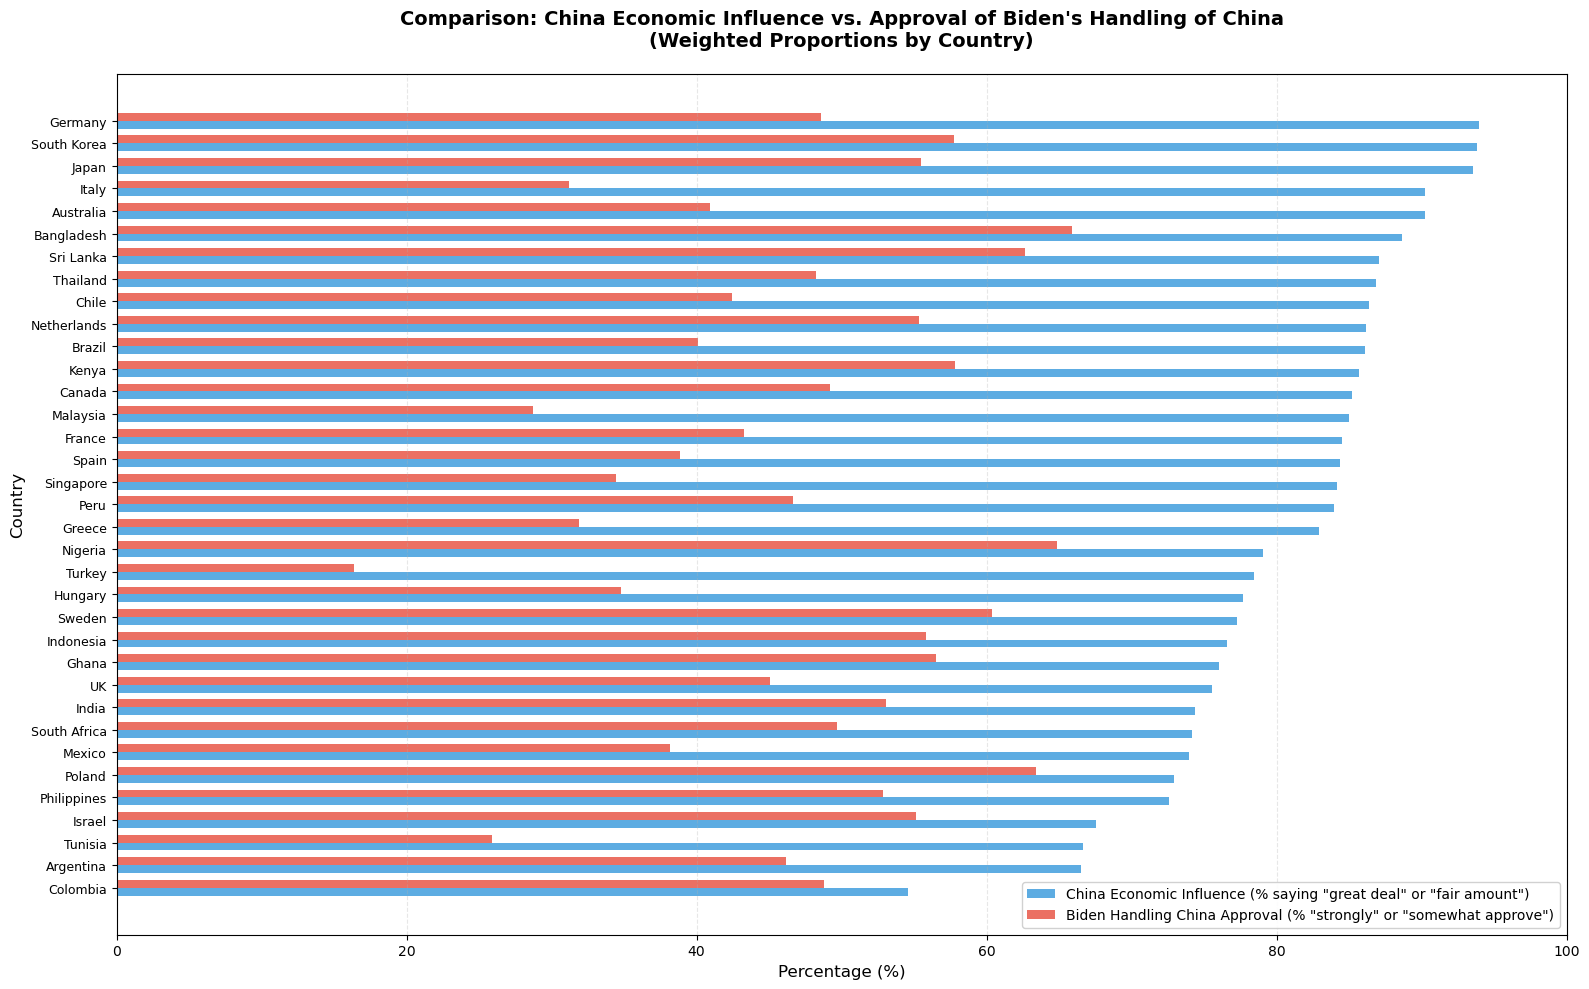

Summary Statistics (Weighted Proportions):

Number of countries: 35

China Economic Influence (% saying China has influence):
  Mean: 80.6%
  Range: 54.6% - 94.0%

Biden Handling China Approval (% approving):
  Mean: 47.0%
  Range: 16.4% - 65.9%


In [35]:
# Grouped Bar Chart: Comparing uspres_china vs china_influ_econ across countries
# Using weighted proportions (appropriate for ordinal variables)

# Filter to valid responses (1-4) for both variables
valid_data = pew[
    pew['uspres_china'].isin(['1', '2', '3', '4']) & 
    pew['china_influ_econ'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'uspres_china', 'china_influ_econ'])

# Calculate weighted proportions for each country
# For ordinal variables, we use proportions, not means
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For uspres_china: % who approve (1 or 2: strongly/somewhat approve)
    uspres_approve = country_data[country_data['uspres_china'].isin(['1', '2'])]['weight'].sum()
    uspres_approve_pct = (uspres_approve / total_weight) * 100
    
    # For china_influ_econ: % who say China has influence (1 or 2: great deal/fair amount)
    econ_influence = country_data[country_data['china_influ_econ'].isin(['1', '2'])]['weight'].sum()
    econ_influence_pct = (econ_influence / total_weight) * 100
    
    country_stats[country] = {
        'uspres_approve_pct': uspres_approve_pct,
        'econ_influence_pct': econ_influence_pct
    }

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(country_stats).T
# Sort by economic influence percentage for better visualization
plot_df = plot_df.sort_values('econ_influence_pct', ascending=True)

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(16, 10))

# Set up positions for bars
x = np.arange(len(plot_df.index))
width = 0.35  # Width of the bars

# Create bars
bars1 = ax.barh(x - width/2, plot_df['econ_influence_pct'], width, 
                label='China Economic Influence (% saying "great deal" or "fair amount")', 
                color='#3498db', alpha=0.8)
bars2 = ax.barh(x + width/2, plot_df['uspres_approve_pct'], width, 
                label='Biden Handling China Approval (% "strongly" or "somewhat approve")', 
                color='#e74c3c', alpha=0.8)

# Customize the plot
ax.set_ylabel('Country', fontsize=12)
ax.set_xlabel('Percentage (%)', fontsize=12)
ax.set_title('Comparison: China Economic Influence vs. Approval of Biden\'s Handling of China\n(Weighted Proportions by Country)',
             fontsize=14, fontweight='bold', pad=20)
ax.set_yticks(x)
ax.set_yticklabels(plot_df.index, fontsize=9)
ax.legend(loc='lower right', framealpha=0.9, fontsize=10)
ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics (Weighted Proportions):")
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nChina Economic Influence (% saying China has influence):")
print(f"  Mean: {plot_df['econ_influence_pct'].mean():.1f}%")
print(f"  Range: {plot_df['econ_influence_pct'].min():.1f}% - {plot_df['econ_influence_pct'].max():.1f}%")
print(f"\nBiden Handling China Approval (% approving):")
print(f"  Mean: {plot_df['uspres_approve_pct'].mean():.1f}%")
print(f"  Range: {plot_df['uspres_approve_pct'].min():.1f}% - {plot_df['uspres_approve_pct'].max():.1f}%")



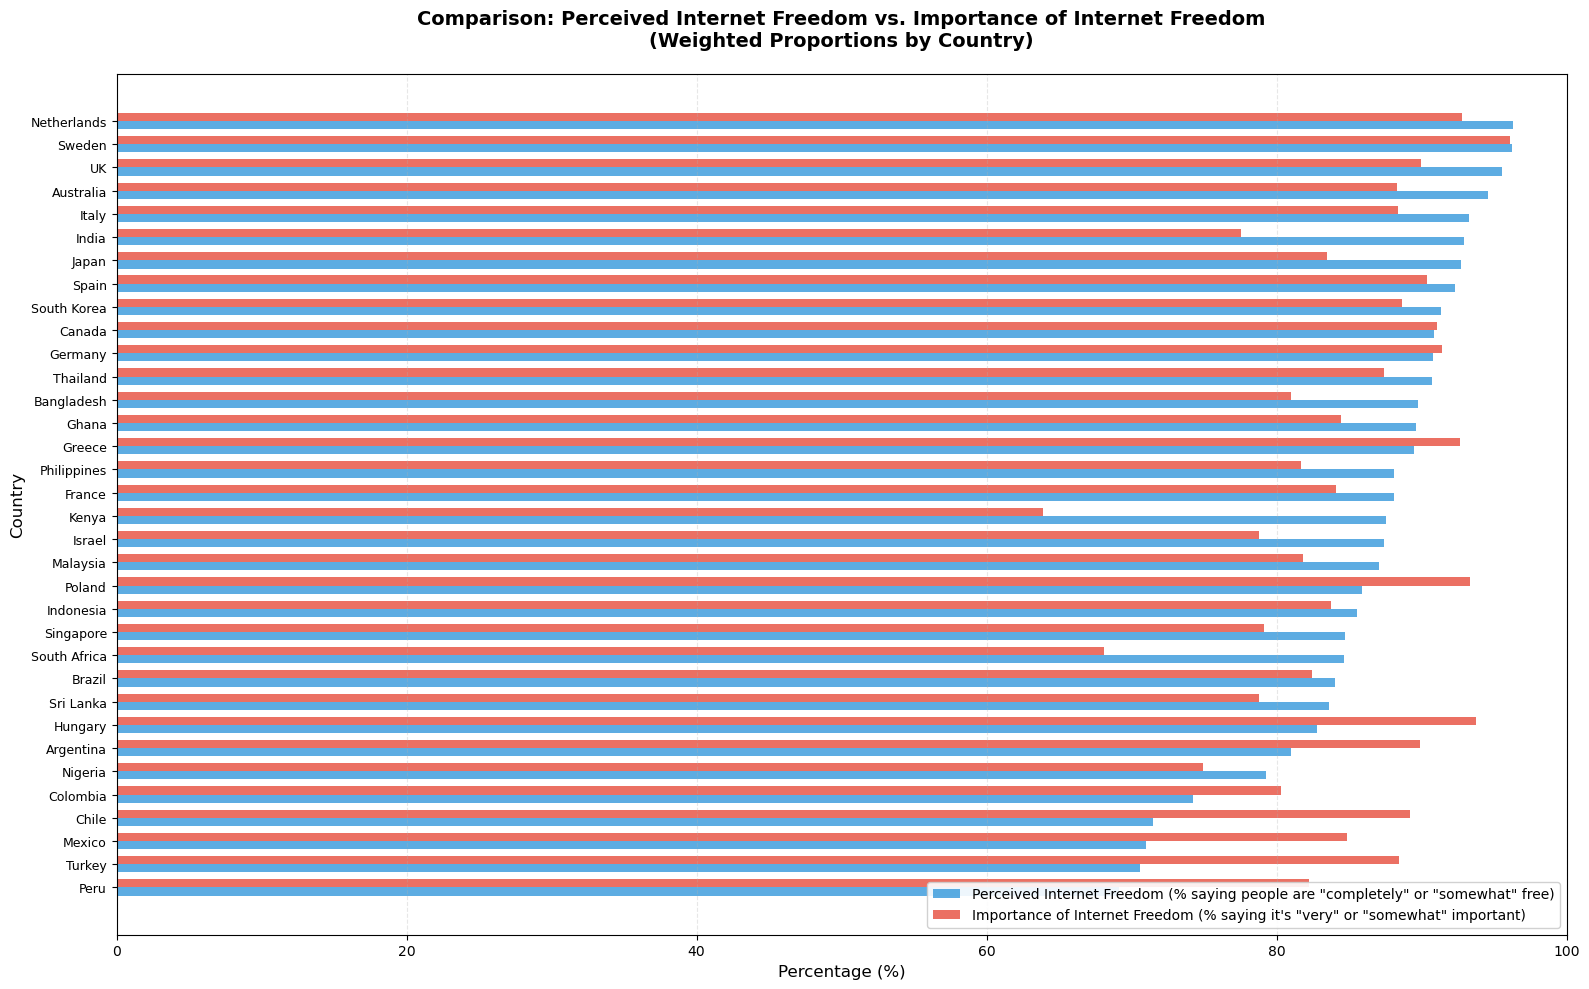

Summary Statistics (Weighted Proportions):

Number of countries: 34

Perceived Internet Freedom (% saying people are free):
  Mean: 86.2%
  Range: 69.1% - 96.3%

Importance of Internet Freedom (% saying it's important):
  Mean: 84.8%
  Range: 63.9% - 96.1%

Spearman Correlation: 0.321 (p-value: 0.0639)
  No statistically significant correlation.


In [ ]:
# Comparison #2: free_internet (perceived freedom) vs internet_freedom (importance)
# Using weighted proportions (appropriate for ordinal variables)

# Filter to valid responses (1-4) for both variables
valid_data = pew[
    pew['free_internet'].isin(['1', '2', '3', '4']) & 
    pew['internet_freedom'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'free_internet', 'internet_freedom'])

# Calculate weighted proportions for each country
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For free_internet: % who say people are "completely" or "somewhat" free (1 or 2)
    # Note: Lower values = more free, so we want 1 or 2
    free_internet_free = country_data[country_data['free_internet'].isin(['1', '2'])]['weight'].sum()
    free_internet_free_pct = (free_internet_free / total_weight) * 100
    
    # For internet_freedom: % who say it's "very important" or "somewhat important" (1 or 2)
    # Note: Lower values = more important, so we want 1 or 2
    internet_freedom_important = country_data[country_data['internet_freedom'].isin(['1', '2'])]['weight'].sum()
    internet_freedom_important_pct = (internet_freedom_important / total_weight) * 100
    
    country_stats[country] = {
        'perceived_free_pct': free_internet_free_pct,  # % who perceive people as free
        'importance_pct': internet_freedom_important_pct  # % who think freedom is important
    }

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(country_stats).T
# Sort by perceived freedom percentage for better visualization
plot_df = plot_df.sort_values('perceived_free_pct', ascending=True)

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(16, 10))

# Set up positions for bars
x = np.arange(len(plot_df.index))
width = 0.35  # Width of the bars

# Create bars
bars1 = ax.barh(x - width/2, plot_df['perceived_free_pct'], width, 
                label='Perceived Internet Freedom (% saying people are "completely" or "somewhat" free)', 
                color='#3498db', alpha=0.8)
bars2 = ax.barh(x + width/2, plot_df['importance_pct'], width, 
                label='Importance of Internet Freedom (% saying it\'s "very" or "somewhat" important)', 
                color='#e74c3c', alpha=0.8)

# Customize the plot
ax.set_ylabel('Country', fontsize=12)
ax.set_xlabel('Percentage (%)', fontsize=12)
ax.set_title('Comparison: Perceived Internet Freedom vs. Importance of Internet Freedom\n(Weighted Proportions by Country)',
             fontsize=14, fontweight='bold', pad=20)
ax.set_yticks(x)
ax.set_yticklabels(plot_df.index, fontsize=9)
ax.legend(loc='lower right', framealpha=0.9, fontsize=10)
ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)

plt.tight_layout()
plt.show()




Median Perceived Freedom: 87.8%
Median Importance: 84.7%

Quadrants:
  Q1 (Top-Right): High Perceived Freedom + High Importance
  Q2 (Top-Left): Low Perceived Freedom + High Importance (Compensatory)
  Q3 (Bottom-Left): Low Perceived Freedom + Low Importance
  Q4 (Bottom-Right): High Perceived Freedom + Low Importance


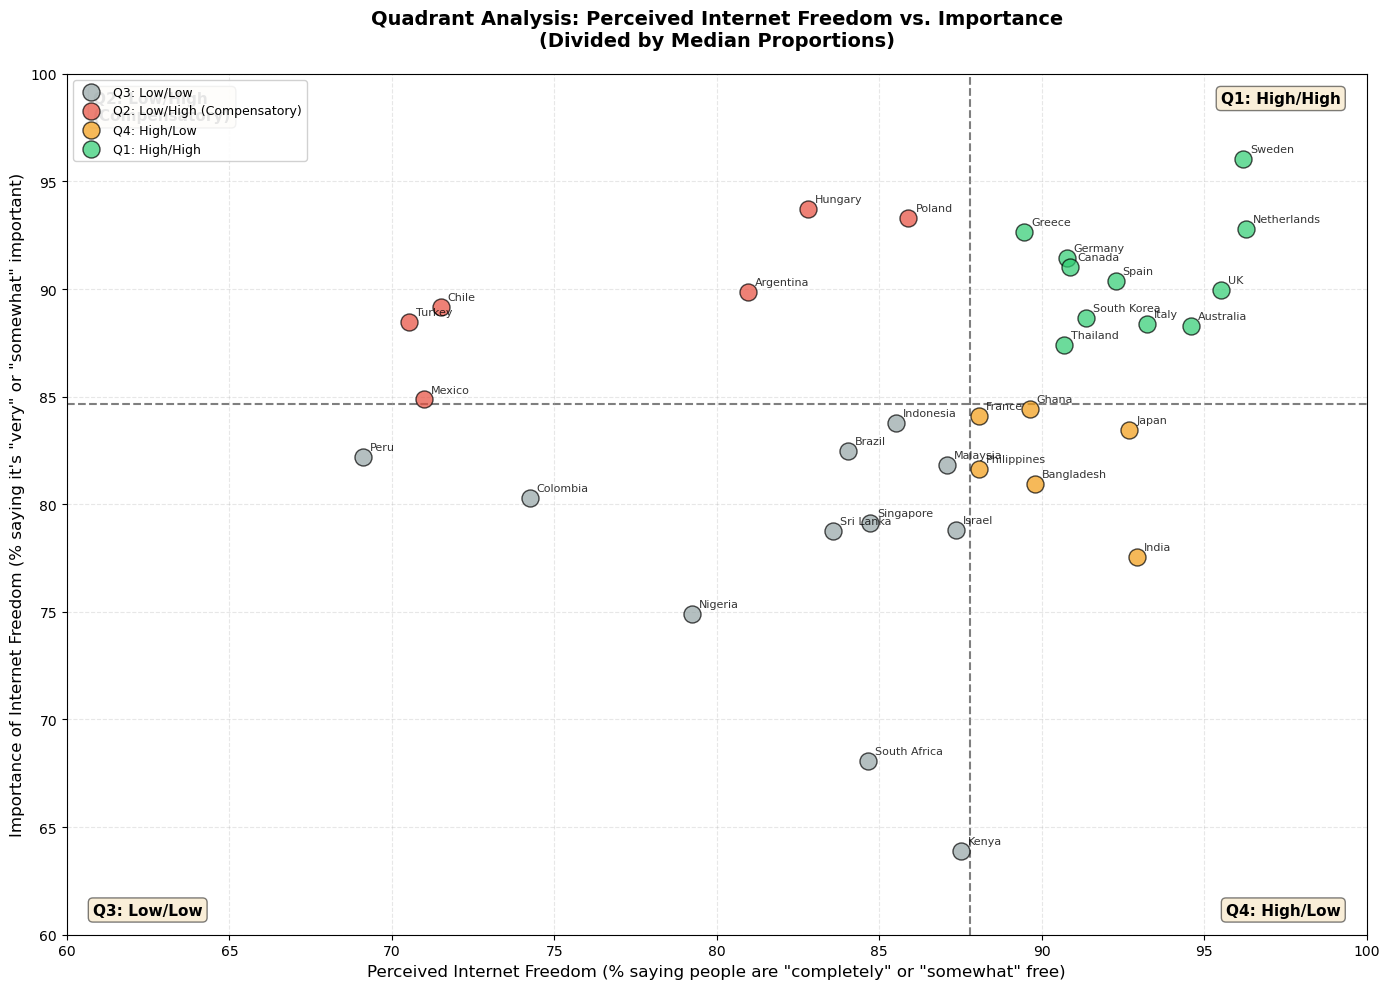

Summary Statistics (Weighted Proportions):

Number of countries: 34

Perceived Internet Freedom (% saying people are free):
  Mean: 86.2%
  Range: 69.1% - 96.3%

Importance of Internet Freedom (% saying it's important):
  Mean: 84.8%
  Range: 63.9% - 96.1%

Spearman Correlation: 0.321 (p-value: 0.0639)
  No statistically significant correlation.


In [43]:
# Quadrant Plot: free_internet (perceived) vs internet_freedom (importance)
# Using medians to divide into quadrants (appropriate for ordinal proportions)

# Reuse plot_df from previous cell
# Calculate medians (not means!) to divide countries into quadrants
median_perceived = plot_df['perceived_free_pct'].median()
median_importance = plot_df['importance_pct'].median()

print(f"Median Perceived Freedom: {median_perceived:.1f}%")
print(f"Median Importance: {median_importance:.1f}%")
print("\nQuadrants:")
print("  Q1 (Top-Right): High Perceived Freedom + High Importance")
print("  Q2 (Top-Left): Low Perceived Freedom + High Importance (Compensatory)")
print("  Q3 (Bottom-Left): Low Perceived Freedom + Low Importance")
print("  Q4 (Bottom-Right): High Perceived Freedom + Low Importance")

# Create quadrant plot
fig, ax = plt.subplots(figsize=(14, 10))

# Define quadrants based on medians
def get_quadrant(row):
    perceived = row['perceived_free_pct']
    importance = row['importance_pct']
    if perceived >= median_perceived and importance >= median_importance:
        return 'Q1: High/High'
    elif perceived < median_perceived and importance >= median_importance:
        return 'Q2: Low/High (Compensatory)'
    elif perceived < median_perceived and importance < median_importance:
        return 'Q3: Low/Low'
    else:
        return 'Q4: High/Low'

plot_df['quadrant'] = plot_df.apply(get_quadrant, axis=1)

# Color map for quadrants
colors = {
    'Q1: High/High': '#2ecc71',  # Green
    'Q2: Low/High (Compensatory)': '#e74c3c',  # Red
    'Q3: Low/Low': '#95a5a6',  # Gray
    'Q4: High/Low': '#f39c12'  # Orange
}

# Plot points by quadrant
for quadrant in plot_df['quadrant'].unique():
    quadrant_data = plot_df[plot_df['quadrant'] == quadrant]
    ax.scatter(quadrant_data['perceived_free_pct'], quadrant_data['importance_pct'],
              s=150, alpha=0.7, color=colors[quadrant], 
              edgecolors='black', linewidth=1, label=quadrant, zorder=3)

# Add country labels
for country in plot_df.index:
    ax.annotate(country, 
                (plot_df.loc[country, 'perceived_free_pct'], 
                 plot_df.loc[country, 'importance_pct']),
                fontsize=8, alpha=0.8,
                xytext=(5, 5), textcoords='offset points', zorder=4)

# Draw quadrant lines (using medians)
ax.axvline(x=median_perceived, color='black', linestyle='--', linewidth=1.5, alpha=0.5, zorder=1)
ax.axhline(y=median_importance, color='black', linestyle='--', linewidth=1.5, alpha=0.5, zorder=1)

# Add quadrant labels in corners
ax.text(0.98, 0.98, 'Q1: High/High', transform=ax.transAxes, 
        fontsize=11, fontweight='bold', ha='right', va='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax.text(0.02, 0.98, 'Q2: Low/High\n(Compensatory)', transform=ax.transAxes, 
        fontsize=11, fontweight='bold', ha='left', va='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax.text(0.02, 0.02, 'Q3: Low/Low', transform=ax.transAxes, 
        fontsize=11, fontweight='bold', ha='left', va='bottom',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax.text(0.98, 0.02, 'Q4: High/Low', transform=ax.transAxes, 
        fontsize=11, fontweight='bold', ha='right', va='bottom',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Customize axes
ax.set_xlabel('Perceived Internet Freedom (% saying people are "completely" or "somewhat" free)', 
              fontsize=12)
ax.set_ylabel('Importance of Internet Freedom (% saying it\'s "very" or "somewhat" important)', 
              fontsize=12)
ax.set_title('Quadrant Analysis: Perceived Internet Freedom vs. Importance\n(Divided by Median Proportions)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--', zorder=0)
ax.set_xlim(60, 100)
ax.set_ylim(60, 100)
ax.legend(loc='upper left', framealpha=0.9, fontsize=9)

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics (Weighted Proportions):")
print(f"\nNumber of countries: {len(plot_df)}")
print(f"\nPerceived Internet Freedom (% saying people are free):")
print(f"  Mean: {plot_df['perceived_free_pct'].mean():.1f}%")
print(f"  Range: {plot_df['perceived_free_pct'].min():.1f}% - {plot_df['perceived_free_pct'].max():.1f}%")
print(f"\nImportance of Internet Freedom (% saying it's important):")
print(f"  Mean: {plot_df['importance_pct'].mean():.1f}%")
print(f"  Range: {plot_df['importance_pct'].min():.1f}% - {plot_df['importance_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df['perceived_free_pct'], plot_df['importance_pct'])
print(f"\nSpearman Correlation: {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  Statistically significant correlation!")
else:
    print("  No statistically significant correlation.")


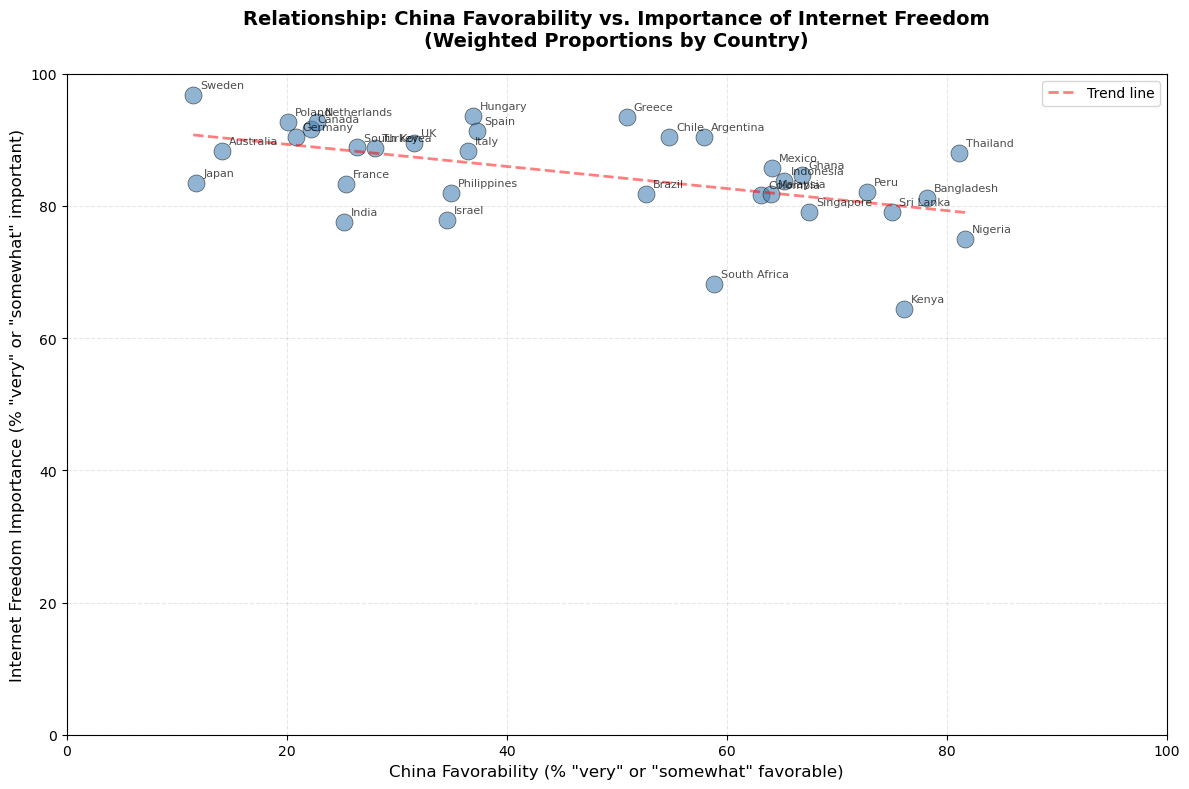

Summary Statistics (Weighted Proportions):

Number of countries: 34

China Favorability (% favorable):
  Mean: 46.2%
  Range: 11.5% - 81.7%

Internet Freedom Importance (% saying it's important):
  Mean: 84.9%
  Range: 64.4% - 96.8%

Spearman Correlation: -0.533 (p-value: 0.0012)
  Statistically significant correlation!


In [41]:
# Scatterplot to visualize the correlation between fav_china and internet_freedom
fig, ax = plt.subplots(figsize=(12, 8))

# Plot points for each country
ax.scatter(plot_df_china['fav_china_favorable_pct'], 
           plot_df_china['internet_freedom_important_pct'], 
           s=150, alpha=0.6, color='steelblue', edgecolors='black', linewidth=0.5)

# Add country labels
for country in plot_df_china.index:
    ax.annotate(country, 
                (plot_df_china.loc[country, 'fav_china_favorable_pct'], 
                 plot_df_china.loc[country, 'internet_freedom_important_pct']),
                fontsize=8, alpha=0.7,
                xytext=(5, 5), textcoords='offset points')

# Add trend line (optional - helps visualize correlation)
from scipy import stats
z = np.polyfit(plot_df_china['fav_china_favorable_pct'], 
               plot_df_china['internet_freedom_important_pct'], 1)
p = np.poly1d(z)
ax.plot(plot_df_china['fav_china_favorable_pct'], 
        p(plot_df_china['fav_china_favorable_pct']), 
        "r--", alpha=0.5, linewidth=2, label='Trend line')

ax.set_xlabel('China Favorability (% "very" or "somewhat" favorable)', fontsize=12)
ax.set_ylabel('Internet Freedom Importance (% "very" or "somewhat" important)', fontsize=12)
ax.set_title('Relationship: China Favorability vs. Importance of Internet Freedom\n(Weighted Proportions by Country)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend()
plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics (Weighted Proportions):")
print(f"\nNumber of countries: {len(plot_df_china)}")
print(f"\nChina Favorability (% favorable):")
print(f"  Mean: {plot_df_china['fav_china_favorable_pct'].mean():.1f}%")
print(f"  Range: {plot_df_china['fav_china_favorable_pct'].min():.1f}% - {plot_df_china['fav_china_favorable_pct'].max():.1f}%")
print(f"\nInternet Freedom Importance (% saying it's important):")
print(f"  Mean: {plot_df_china['internet_freedom_important_pct'].mean():.1f}%")
print(f"  Range: {plot_df_china['internet_freedom_important_pct'].min():.1f}% - {plot_df_china['internet_freedom_important_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df_china['fav_china_favorable_pct'], plot_df_china['internet_freedom_important_pct'])
print(f"\nSpearman Correlation: {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  Statistically significant correlation!")
else:
    print("  No statistically significant correlation.")

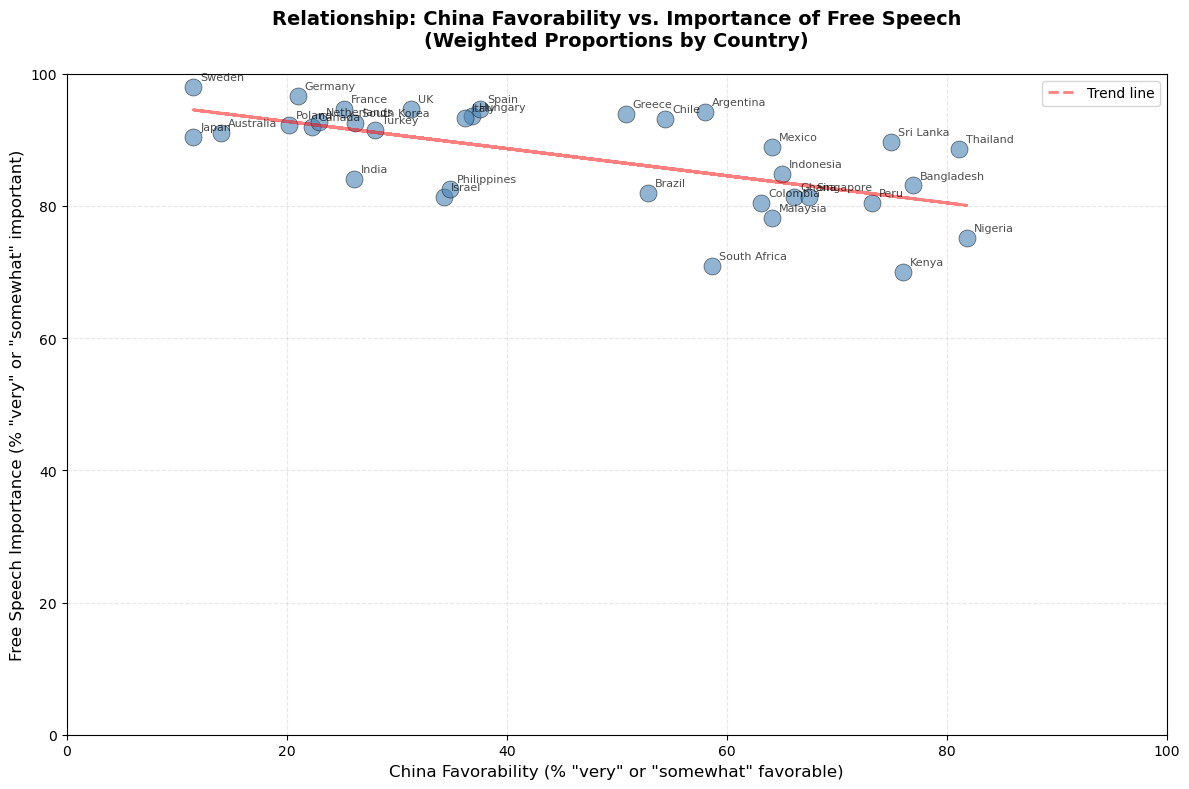

Summary Statistics (Weighted Proportions):

Number of countries: 34

China Favorability (% favorable):
  Mean: 46.1%
  Range: 11.5% - 81.8%

Free Speech Importance (% saying it's important):
  Mean: 87.4%
  Range: 70.0% - 98.1%

Spearman Correlation: -0.608 (p-value: 0.0001)
  Statistically significant correlation!


In [44]:
# Scatterplot: fav_china vs free_speech (importance)
# Using weighted proportions (appropriate for ordinal variables)

# Filter to valid responses (1-4) for both variables
valid_data = pew[
    pew['fav_china'].isin(['1', '2', '3', '4']) & 
    pew['free_speech'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_china', 'free_speech'])

# Calculate weighted proportions for each country
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For fav_china: % who are favorable (1 or 2: very/somewhat favorable)
    fav_china_favorable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
    fav_china_favorable_pct = (fav_china_favorable / total_weight) * 100
    
    # For free_speech: % who say it's "very important" or "somewhat important" (1 or 2)
    free_speech_important = country_data[country_data['free_speech'].isin(['1', '2'])]['weight'].sum()
    free_speech_important_pct = (free_speech_important / total_weight) * 100
    
    country_stats[country] = {
        'fav_china_favorable_pct': fav_china_favorable_pct,
        'free_speech_important_pct': free_speech_important_pct
    }

# Convert to DataFrame for easier plotting
plot_df_speech = pd.DataFrame(country_stats).T

# Create scatterplot
fig, ax = plt.subplots(figsize=(12, 8))

# Plot points for each country
ax.scatter(plot_df_speech['fav_china_favorable_pct'], 
           plot_df_speech['free_speech_important_pct'], 
           s=150, alpha=0.6, color='steelblue', edgecolors='black', linewidth=0.5)

# Add country labels
for country in plot_df_speech.index:
    ax.annotate(country, 
                (plot_df_speech.loc[country, 'fav_china_favorable_pct'], 
                 plot_df_speech.loc[country, 'free_speech_important_pct']),
                fontsize=8, alpha=0.7,
                xytext=(5, 5), textcoords='offset points')

# Add trend line (optional - helps visualize correlation)
from scipy import stats
z = np.polyfit(plot_df_speech['fav_china_favorable_pct'], 
               plot_df_speech['free_speech_important_pct'], 1)
p = np.poly1d(z)
ax.plot(plot_df_speech['fav_china_favorable_pct'], 
        p(plot_df_speech['fav_china_favorable_pct']), 
        "r--", alpha=0.5, linewidth=2, label='Trend line')

ax.set_xlabel('China Favorability (% "very" or "somewhat" favorable)', fontsize=12)
ax.set_ylabel('Free Speech Importance (% "very" or "somewhat" important)', fontsize=12)
ax.set_title('Relationship: China Favorability vs. Importance of Free Speech\n(Weighted Proportions by Country)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend()
plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics (Weighted Proportions):")
print(f"\nNumber of countries: {len(plot_df_speech)}")
print(f"\nChina Favorability (% favorable):")
print(f"  Mean: {plot_df_speech['fav_china_favorable_pct'].mean():.1f}%")
print(f"  Range: {plot_df_speech['fav_china_favorable_pct'].min():.1f}% - {plot_df_speech['fav_china_favorable_pct'].max():.1f}%")
print(f"\nFree Speech Importance (% saying it's important):")
print(f"  Mean: {plot_df_speech['free_speech_important_pct'].mean():.1f}%")
print(f"  Range: {plot_df_speech['free_speech_important_pct'].min():.1f}% - {plot_df_speech['free_speech_important_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df_speech['fav_china_favorable_pct'], 
                                 plot_df_speech['free_speech_important_pct'])
print(f"\nSpearman Correlation: {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  Statistically significant correlation!")
else:
    print("  No statistically significant correlation.")

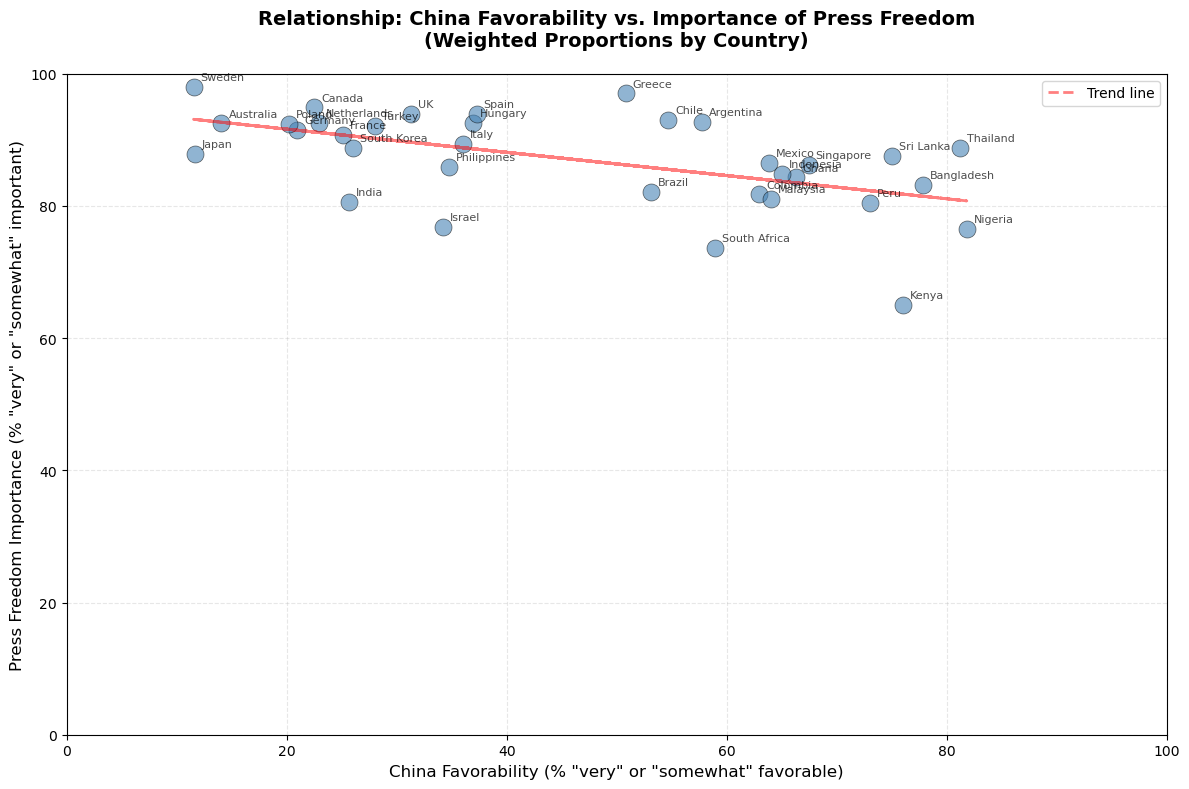

Summary Statistics (Weighted Proportions):

Number of countries: 34

China Favorability (% favorable):
  Mean: 46.1%
  Range: 11.5% - 81.8%

Press Freedom Importance (% saying it's important):
  Mean: 87.0%
  Range: 65.0% - 98.0%

Spearman Correlation: -0.554 (p-value: 0.0007)
  Statistically significant correlation!


In [45]:
# Scatterplot: fav_china vs press_freedom (importance)
# Using weighted proportions (appropriate for ordinal variables)

# Filter to valid responses (1-4) for both variables
valid_data = pew[
    pew['fav_china'].isin(['1', '2', '3', '4']) & 
    pew['press_freedom'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_china', 'press_freedom'])

# Calculate weighted proportions for each country
country_stats = {}

for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    # For fav_china: % who are favorable (1 or 2: very/somewhat favorable)
    fav_china_favorable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
    fav_china_favorable_pct = (fav_china_favorable / total_weight) * 100
    
    # For press_freedom: % who say it's "very important" or "somewhat important" (1 or 2)
    press_freedom_important = country_data[country_data['press_freedom'].isin(['1', '2'])]['weight'].sum()
    press_freedom_important_pct = (press_freedom_important / total_weight) * 100
    
    country_stats[country] = {
        'fav_china_favorable_pct': fav_china_favorable_pct,
        'press_freedom_important_pct': press_freedom_important_pct
    }

# Convert to DataFrame for easier plotting
plot_df_press = pd.DataFrame(country_stats).T

# Create scatterplot
fig, ax = plt.subplots(figsize=(12, 8))

# Plot points for each country
ax.scatter(plot_df_press['fav_china_favorable_pct'], 
           plot_df_press['press_freedom_important_pct'], 
           s=150, alpha=0.6, color='steelblue', edgecolors='black', linewidth=0.5)

# Add country labels
for country in plot_df_press.index:
    ax.annotate(country, 
                (plot_df_press.loc[country, 'fav_china_favorable_pct'], 
                 plot_df_press.loc[country, 'press_freedom_important_pct']),
                fontsize=8, alpha=0.7,
                xytext=(5, 5), textcoords='offset points')

# Add trend line (optional - helps visualize correlation)
from scipy import stats
z = np.polyfit(plot_df_press['fav_china_favorable_pct'], 
               plot_df_press['press_freedom_important_pct'], 1)
p = np.poly1d(z)
ax.plot(plot_df_press['fav_china_favorable_pct'], 
        p(plot_df_press['fav_china_favorable_pct']), 
        "r--", alpha=0.5, linewidth=2, label='Trend line')

ax.set_xlabel('China Favorability (% "very" or "somewhat" favorable)', fontsize=12)
ax.set_ylabel('Press Freedom Importance (% "very" or "somewhat" important)', fontsize=12)
ax.set_title('Relationship: China Favorability vs. Importance of Press Freedom\n(Weighted Proportions by Country)',
             fontsize=14, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend()
plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary Statistics (Weighted Proportions):")
print(f"\nNumber of countries: {len(plot_df_press)}")
print(f"\nChina Favorability (% favorable):")
print(f"  Mean: {plot_df_press['fav_china_favorable_pct'].mean():.1f}%")
print(f"  Range: {plot_df_press['fav_china_favorable_pct'].min():.1f}% - {plot_df_press['fav_china_favorable_pct'].max():.1f}%")
print(f"\nPress Freedom Importance (% saying it's important):")
print(f"  Mean: {plot_df_press['press_freedom_important_pct'].mean():.1f}%")
print(f"  Range: {plot_df_press['press_freedom_important_pct'].min():.1f}% - {plot_df_press['press_freedom_important_pct'].max():.1f}%")

# Calculate correlation (using Spearman since these are ordinal proportions)
from scipy.stats import spearmanr
correlation, p_value = spearmanr(plot_df_press['fav_china_favorable_pct'], 
                                 plot_df_press['press_freedom_important_pct'])
print(f"\nSpearman Correlation: {correlation:.3f} (p-value: {p_value:.4f})")
if p_value < 0.05:
    print("  Statistically significant correlation!")
else:
    print("  No statistically significant correlation.")

# 4. Discussion

# 5. Limitations

# Bibliography

Packages used []